### Prédiction du prix des billets d'avion 
L'objectif de ce projet est de prédire le prix le des billets d'avion en fonction de diverses caractéristiques telles que la date de reservation , la durée du vol , le nombre d'escales , etc.  Nous allons effectuer une exploration de données (EDA) pour comprendre les relations entre differentes variables et le prix des billets . Ensuite nous developperons un modele  predictive pour estimer le prix des billets en fonction des caracteristiques disponibles.

#### Index 

  * Les données 
  * Analyse technique 
     * Analyse univariée
     * Analyse bivariée

  * Formuler et tester des hypotheses  

In [1]:
 
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
import plotly.express as px
import os 

In [7]:
os.chdir("/Users/thomasalaby/Desktop/ML-PRO/ML_PROJECT/flight_price_prediction/data/processed")

In [8]:
os.getcwd()

'/Users/thomasalaby/Desktop/ML-PRO/ML_PROJECT/flight_price_prediction/data/processed'

In [ ]:
# Chargement des données : 
df = pd.read_csv("train.csv",)
df.head(5)

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,78798,AirAsia,I5-942,Mumbai,Afternoon,one,Evening,Chennai,Economy,4.33,13,5939
1,42796,Air_India,AI-636,Delhi,Afternoon,one,Morning,Chennai,Economy,19.83,48,3988
2,118628,SpiceJet,SG-4009,Bangalore,Early_Morning,zero,Early_Morning,Chennai,Economy,1.08,38,1606
3,61731,Indigo,6E-354,Mumbai,Afternoon,two_or_more,Night,Kolkata,Economy,9.92,2,21483
4,25678,AirAsia,I5-747,Delhi,Evening,one,Late_Night,Kolkata,Economy,6.58,33,3175


## **Analyse fondamentale** 

#### **What Quoi?**. 
**Sens des variables**
1. **airline** :nom de la compagnie aerienne (categorielle nominale) 
2. **flight** :code de voyage de l'avion (categorielle nominale)
3. **source_city** :ville de decollage (categorelle nominale)
4. **depature_time** :heure de depart qui a été transformé en regroupant des heures en bandes (categorielle ordinale)
5. **stops** :nombre d'escale durant le trajet (categorielle ordinale)
6. **arrival_time** :heure d'arrivé qui a été modifié en regroupant les heures en bande (categorielle ordinale)
7. **destination_city** :ville de destination ( categorielle nominale)
8. **class** :la classe du siege (categorielle ordinale)
9. **duration** :temps de trajet  (continue)
10. **day_left** :variable obtenue en faisant la difference entre le jour de reservation et ce lui du jour de depart (categorielle ordinale)
11. **price** :variable cible representant le prix du billet (continue)

L' entité représenté est un client rattaché à une compagnie aérienne 

#### **Who Qui?**
Identification des parties prenantes impliquées dans la collecte. 

**Collecteurss des données** :SHubham Bathwal. 
**Provenance** Easemytrip website. 
**Responsabilité et expertise** :Etudiant chercheur à Praxis Business school. 
**Beneficiaire des données** données ouvertes au public sur kaggle


#### **When Quand ?**
**Periode de collecte**: La periode s'étale sur 50 jours(11 fevrier au 31 mars 2022).     
**Frequence de mise à jour**: hebdomadaire (dernière mise à jour remonte à 5ans). 
**Pertinence temporelle**: Données obsolette au vue de la dernière mise à jour 

#### **Where Où ?**
**Origine géographique**: Inde 

#### **How Comment ?**
**Méthode de collecte** : web scraping sur le site Easemytrip.  
**Protocole de collecte** : Information non renseigné sur kaggle.  
**Qualité des données** Information non renseignée sur kaggle.    
**Outils et methodologies** Octoparse scraping tool 

#### **Why ?**
**Objective initial** : Repondre aux questions suivantes :
  * Est-ce que le prix des billets varient en fonction de la compagnie aérienne ?
  * comment les prix sont-ils affectés quand les billets sont achétés 1 à 2 jours avant le depart?  
  * Les prix changent-ils en fonction de l'heure de depart et celui de l'arrivée ?
  * Comment les prix varient-ils entre la classe bussiness et la classe économique?  
  * comment les prix varient ils en fonction des villes de depart et d'arrivé. 
  
**Utilisation prévue** modélisation des prix de billets d'avion pour uune prediction des futures billets.   
**Motivation de la mise à disposition**: Objectif de recherche . 

## **Analyse technique**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210107 entries, 0 to 210106
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        210107 non-null  int64  
 1   airline           210107 non-null  str    
 2   flight            210107 non-null  str    
 3   source_city       210107 non-null  str    
 4   departure_time    210107 non-null  str    
 5   stops             210107 non-null  str    
 6   arrival_time      210107 non-null  str    
 7   destination_city  210107 non-null  str    
 8   class             210107 non-null  str    
 9   duration          210107 non-null  float64
 10  days_left         210107 non-null  int64  
 11  price             210107 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 19.2 MB


- Le jeu d'entrainement comporte 210107 individus 
- 11 caracteristiques reparties comme suite :
  * 2 variables continues 
  * 4 variables discrets (classe nominale)
  * 5 variables discrets (classe ordinale )
- Aucune caracteristique ne presente de valeur manquante 

#### Analyse univariée 

##### Variable cible

In [6]:
df['price'].describe()

count    210107.000000
mean      20902.814699
std       22702.079328
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

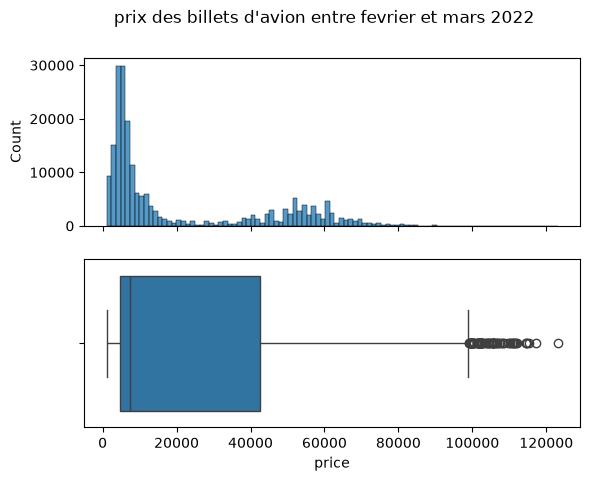

In [7]:
fig, ax =plt.subplots(2,1,sharex=True)
plt.suptitle("prix des billets d'avion entre fevrier et mars 2022")
sns.histplot(df,x='price',ax=ax[0])
sns.boxplot(df,x="price", ax=ax[1])



plt.show()

* les individus depensent en moyenne environ 20903 roupies pour se prendre un billet d'avion . 
* il y a par contre un écart considerabale entres le prix des billets au vu de l'ecart type qui est plus élévé que le prix moyen d'un billet d'avion (phénomène qui peut s'expliquer par le prix de la classe des sièges) 
* le prix le plus elevé était à 123071 roupies pendant que le prix le plus bas affichait 1105 roupies
* enfin 50% de ces plus de 210 milles clients debourssaient moins de 7500 roupies pour l'achat de billet 

##### Variable continue

In [8]:
df["duration"].describe()

count    210107.000000
mean         12.222467
std           7.195453
min           0.830000
25%           6.830000
50%          11.250000
75%          16.170000
max          49.830000
Name: duration, dtype: float64

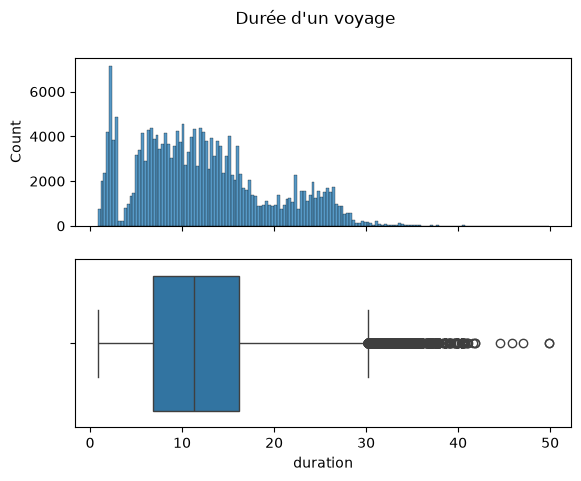

In [9]:
fig ,ax =plt.subplots(2,1, sharex=True)
plt.suptitle("Durée d'un voyage")
sns.histplot(df,x='duration',ax=ax[0])
sns.boxplot(df,x='duration',ax=ax[1])
plt.show()

* la durée moyenne de trajet se situe entre 5 et 19h 
* le trajet le plus long est de pres de 50h
* 50% des trajets dure moins de 12h
* un voyage de plus de 30h peut s'averer anormale 

##### Variables discrètes

In [10]:
def var_discrete(dis):
    print(df[dis].value_counts(normalize=True).sort_values(ascending=False)*100)
    if df[dis].nunique() < 4:
        df[dis].value_counts().sort_values().plot(kind='pie')
    else :
        sns.countplot(df,x=dis, hue=dis,stat='percent',legend='full',orient='v')
   
    

airline
Vistara      42.603055
Air_India    26.954361
Indigo       14.331269
GO_FIRST      7.696555
AirAsia       5.378688
SpiceJet      3.036072
Name: proportion, dtype: float64


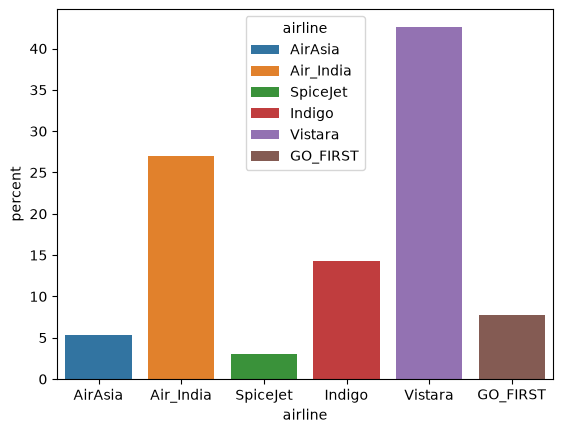

In [11]:

var_discrete('airline')

* Les compagnies Vistara, Air_India, et Indigo concentre près de 84% des clients .
* Vistara vient en tête avec une part de 43% du marché 
* AirAsia,SpiceJet et Gofirst se partagent les 15% des clients restant 

source_city
Delhi        20.455292
Mumbai       20.281095
Bangalore    17.356871
Kolkata      15.486395
Hyderabad    13.548335
Chennai      12.872013
Name: proportion, dtype: float64


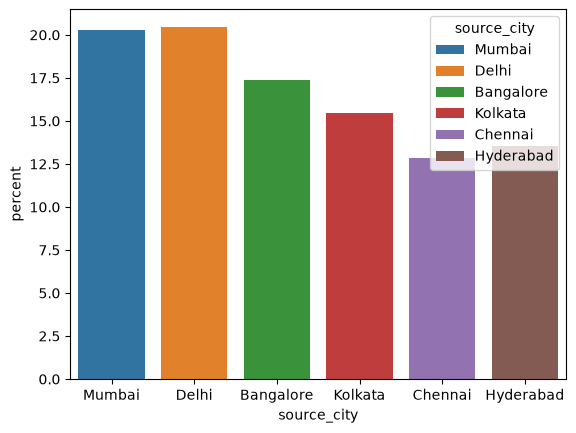

In [12]:
var_discrete('source_city')

* Dehli et Mumbai sont des villes prisés pour le départ (ville mégalopole concentrant une forte population)

departure_time
Morning          23.716487
Early_Morning    22.363843
Evening          21.640878
Night            15.942353
Afternoon        15.899518
Late_Night        0.436920
Name: proportion, dtype: float64


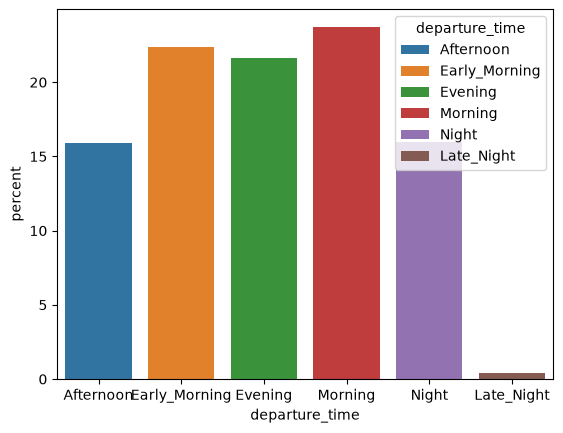

In [13]:
var_discrete('departure_time')

* Les  clients préfèrent plus decoller en matinée (46% d'entre eux ) quand 36% par contre privillegie les vogage de nuit 

stops
one            83.566944
zero           12.025301
two_or_more     4.407754
Name: proportion, dtype: float64


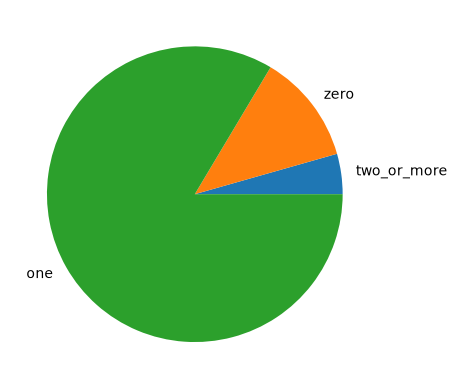

In [14]:
var_discrete('stops')

* près de 88% des voyages s'effectuent avec au moins un escalle . 
* 83 % s'effectue avec exactement un escalle

arrival_time
Night            30.630583
Evening          26.044349
Morning          20.837002
Afternoon        12.750646
Early_Morning     5.135955
Late_Night        4.601465
Name: proportion, dtype: float64


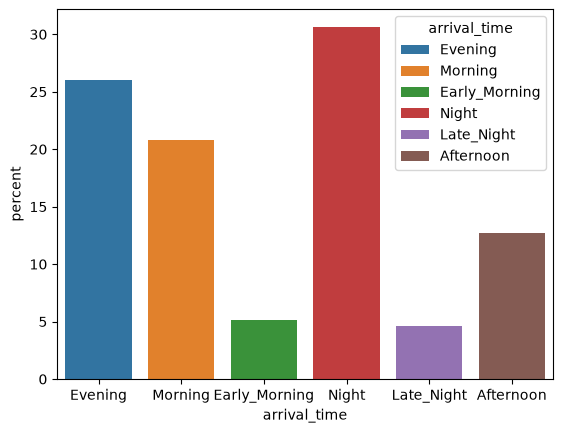

In [15]:
var_discrete('arrival_time')

* Plus de 56% des individus préfèrent des heures de soirée comme heure d'arrivé (chose tout à fait normale puisqu'il sont les memes qui choisisent comme heure de depart la matinée). 
* 33% des individues choisisent comme heure d'arrivée la journée.

destination_city
Mumbai       19.720428
Delhi        19.059336
Bangalore    16.987535
Kolkata      16.571556
Hyderabad    14.220849
Chennai      13.440295
Name: proportion, dtype: float64


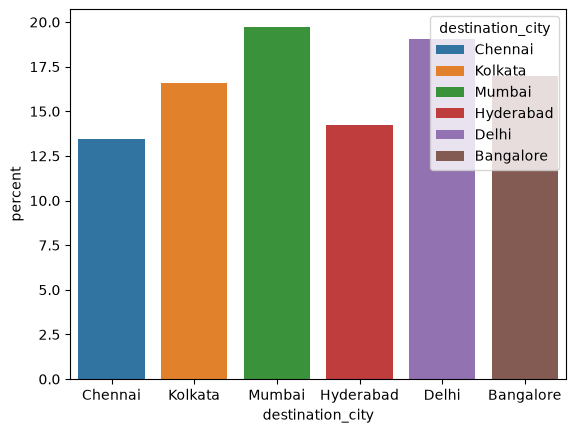

In [16]:
var_discrete('destination_city')

* Les destination priorisées restent Mumbai et Dehli suivie de près par Bangalore 

class
Economy     68.823028
Business    31.176972
Name: proportion, dtype: float64


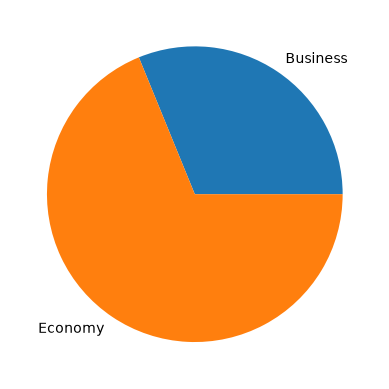

In [17]:
var_discrete('class')

* Près de 69 % voyagent en class encomique 
* 31% voyagent quant à eux en bussiness

In [50]:
#var_discrete('days_left')

#### Analyses univariée

**Prix/durée du vol**

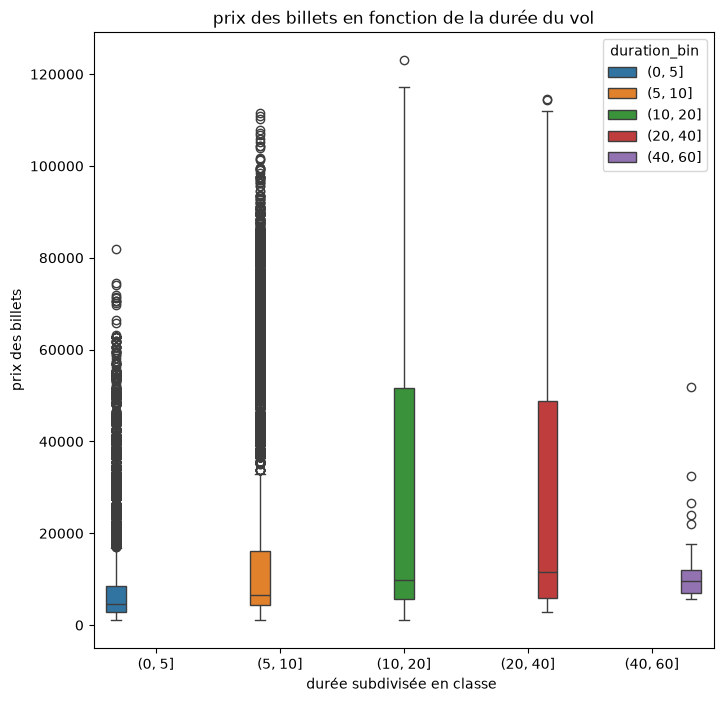

In [18]:
df["duration_bin"] = pd.cut(df["duration"], bins=[0,5,10,20,40,60])
plt.figure(figsize=(8,8))
sns.boxplot(df,x='duration_bin',y='price',hue='duration_bin')
plt.title('prix des billets en fonction de la durée du vol')
plt.xlabel('durée subdivisée en classe ')
plt.ylabel('prix des billets')
plt.show()       
    

* Les prix semblent evoluer en fonction de la durée du voyage . 
* argument à verifier avec un test d'hypothèse 

**Prix/airline**

In [37]:
plt.figure(figsize=(8,8))
px.box(df,x='airline',y='price',color='airline',title='prix des billets en fonction de la companie aérienne')





<Figure size 800x800 with 0 Axes>

* les prix des billets medians  à Air_India et Vistara sont élévés tandis qu'ils restent relativement bas dans les autres compagnies 
* Ils semblent donc que le prix des billets semblent être influé par la compagnie aérienne (Hypothèse à tester)

**Price/source_city**


In [39]:
plt.figure(figsize=(8,8))
px.box(df,x='source_city',y='price',color='source_city',title='prix des billets en fonction de la ville de départ du vol')




<Figure size 800x800 with 0 Axes>

* Les 6 villes pour le decollage presentent pratiquement les mêmes distributions au niveau du prix 

**price/departure_time**

In [40]:
plt.figure(figsize=(8,8))
px.box(df,x='departure_time',y='price',color='departure_time',title="prix des billets en fonction de l'heure de depart")




<Figure size 800x800 with 0 Axes>

* Distributions disportionnée surtout pour les prix de billet d'avion dans l'apres midi et tard dans la nuit . 
* l'heure de depart presente un faceur important dans la variation des prix (à verifier avec un test )

**price/stops**

In [41]:
plt.figure(figsize=(8,8))
px.box(df,x='stops',y='price',color='stops',title='prix des billets en fonction des escalles')




<Figure size 800x800 with 0 Axes>

Le prix semble dependre du numbre de stops (a verifier )

**price/arrival_time**

In [42]:
plt.figure(figsize=(8,8))
px.box(df,x='arrival_time',y='price',color='arrival_time',title="prix des billets en fonction de l'heure d'arrivée")




<Figure size 800x800 with 0 Axes>

* prix du billet semble bas à des heures tardives et tôt le matin .
* l'heure d'arrivé est un facteur determinant dans l'estimation des prix


**Price/destination_city**

In [43]:
plt.figure(figsize=(8,8))
px.box(df,x='destination_city',y='price',color='destination_city',title="prix des billets en fonction de la destination d'arrivée")




<Figure size 800x800 with 0 Axes>

**price/clasee**

In [44]:
plt.figure(figsize=(8,8))
px.box(df,x='class',y='price',color='class',title='prix des billets en fonction de la classe du siège')




<Figure size 800x800 with 0 Axes>

le prix est probablement fortement correlé à la classe du siège (verification avec un test d'hypothèse)

**price/day_left**

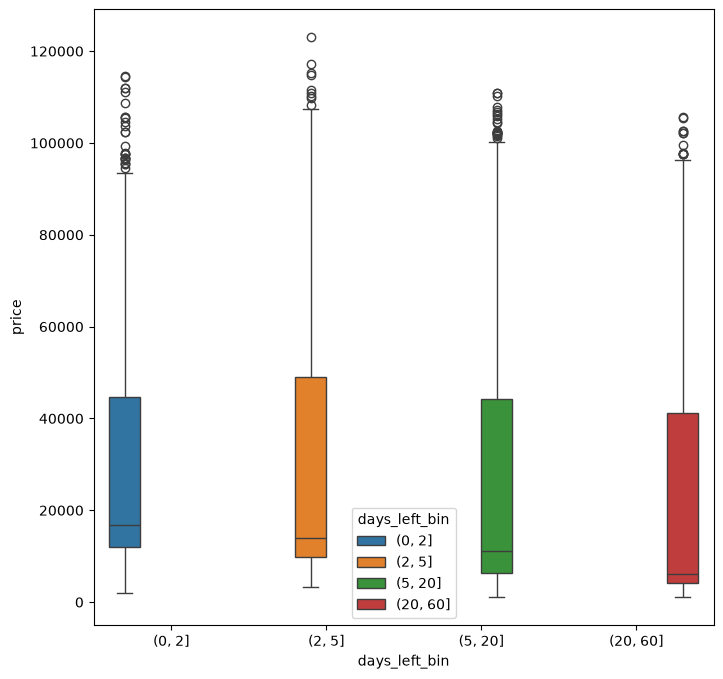

In [72]:
df['days_left_bin']=pd.cut(df["days_left"],bins=[0,2,5,20,60])
plt.figure(figsize=(8,8))
sns.boxplot(df,x='days_left_bin',y="price",hue='days_left_bin')
plt.show()




* le prix median des differentes augment au fur et à mesure qu'on se rapproche de la date de voyage .
* la date semble être un élement pertiennent dans la variation des prix (verification avec un test d'hypothese)